# Fashion-MNIST Image Classification

## CNN vs Random Forest

**Course:** DLBAIPCV01 – Project: Computer Vision  
**Task:** Task 2 – Classifying Fashion Products

### Objective

This project compares two methods for classifying Fashion-MNIST images:

1. Convolutional Neural Network
2. Random Forest Classifier

The models are evaluated using accuracy, precision, recall, F1-score, confusion matrices, training time and class-level performance.

Module 1 — Import libraries

In [77]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Module 2 — Reproducibility

In [78]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


Module 3 — Load Fashion-MNIST

In [79]:
fashion_mnist = keras.datasets.fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Dataset loaded.")

Dataset loaded.


Module 4 — Dataset inspection

In [80]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

print("Total images:", len(X_train) + len(X_test))

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Total images: 70000


Module 5 — Define class names

In [81]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

for i, name in enumerate(class_names):
    print(i, "=", name)

0 = T-shirt/top
1 = Trouser
2 = Pullover
3 = Dress
4 = Coat
5 = Sandal
6 = Shirt
7 = Sneaker
8 = Bag
9 = Ankle boot


Module 6 — Display sample images

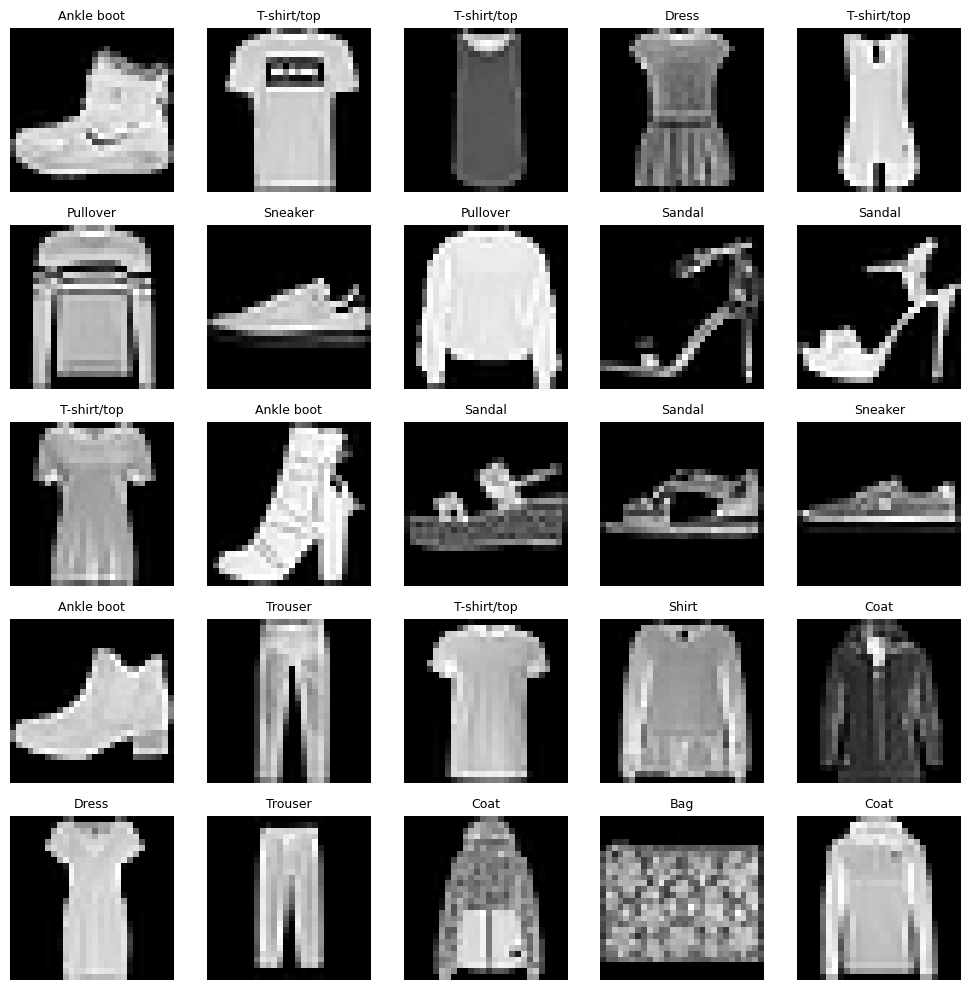

In [82]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

Module 7 — Class distribution

In [83]:
train_labels, train_counts = np.unique(y_train, return_counts=True)
test_labels, test_counts = np.unique(y_test, return_counts=True)

class_distribution = pd.DataFrame({
    "Class ID": train_labels,
    "Class Name": [class_names[i] for i in train_labels],
    "Training Images": train_counts,
    "Test Images": test_counts
})

class_distribution

,Class ID,Class Name,Training Images,Test Images
0,0,T-shirt/top,6000,1000
1,1,Trouser,6000,1000
2,2,Pullover,6000,1000
3,3,Dress,6000,1000
4,4,Coat,6000,1000
5,5,Sandal,6000,1000
6,6,Shirt,6000,1000
7,7,Sneaker,6000,1000
8,8,Bag,6000,1000
9,9,Ankle boot,6000,1000


Module 8 — Inspect pixel values

In [84]:
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())
print("Data type:", X_train.dtype)

Minimum: 0
Maximum: 255
Data type: uint8


Module 9 — Prepare CNN data

In [85]:
X_train_cnn = X_train.astype("float32") / 255.0
X_test_cnn = X_test.astype("float32") / 255.0

X_train_cnn = np.expand_dims(X_train_cnn, axis=-1)
X_test_cnn = np.expand_dims(X_test_cnn, axis=-1)

print("CNN train:", X_train_cnn.shape)
print("CNN test:", X_test_cnn.shape)
print("Pixel range:", X_train_cnn.min(), "to", X_train_cnn.max())

CNN train: (60000, 28, 28, 1)
CNN test: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


Module 10 — Prepare Random Forest data

In [86]:
X_train_rf = X_train.reshape(len(X_train), -1)
X_test_rf = X_test.reshape(len(X_test), -1)

print("RF train:", X_train_rf.shape)
print("RF test:", X_test_rf.shape)

RF train: (60000, 784)
RF test: (10000, 784)


Module 11  Build, Compile, Train and Save CNN

In [57]:
tf.keras.backend.clear_session()

cnn_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),

    keras.layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    keras.layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    keras.layers.Flatten(),

    keras.layers.Dense(
        128,
        activation="relu"
    ),

    keras.layers.Dense(
        10,
        activation="softmax"
    )
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

start_time = time.time()

cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

cnn_training_time = time.time() - start_time

print(
    "\nCNN training time:",
    round(cnn_training_time, 2),
    "seconds"
)

print(
    "Final training accuracy:",
    cnn_history.history["accuracy"][-1]
)

print(
    "Final validation accuracy:",
    cnn_history.history["val_accuracy"][-1]
)

cnn_model.save("trained_cnn.keras")

print("Trained CNN saved successfully.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - accuracy: 0.8019 - loss: 0.5531 - val_accuracy: 0.8633 - val_loss: 0.3854
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.8737 - loss: 0.3480 - val_accuracy: 0.8863 - val_loss: 0.3176
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.8905 - loss: 0.3007 - val_accuracy: 0.8952 - val_loss: 0.2887
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.9011 - loss: 0.2700 - val_accuracy: 0.9000 - val_loss: 0.2760
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 103ms/step - accuracy: 0.9094 - loss: 0.2463 - val_accuracy: 0.9027 - val_loss: 0.2650
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.9176 - loss: 0.2265 - val_accuracy: 0.9065 - val_loss: 0.2567
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.9238 - loss: 0.2080 - val_accuracy: 0.9092 - val_loss: 0.2541
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 100ms/step - accuracy: 0.9297 - loss: 0

Module 12 — CNN training curves

Accuracy

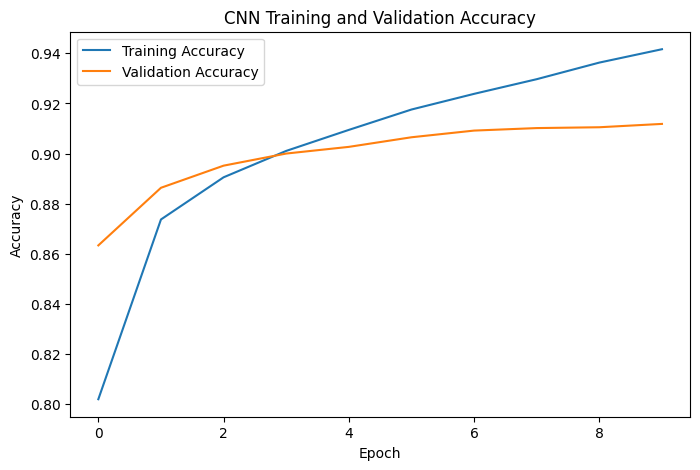

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()

plt.savefig(
    "cnn_accuracy_curve.png",
    bbox_inches="tight"
)

plt.show()

Loss

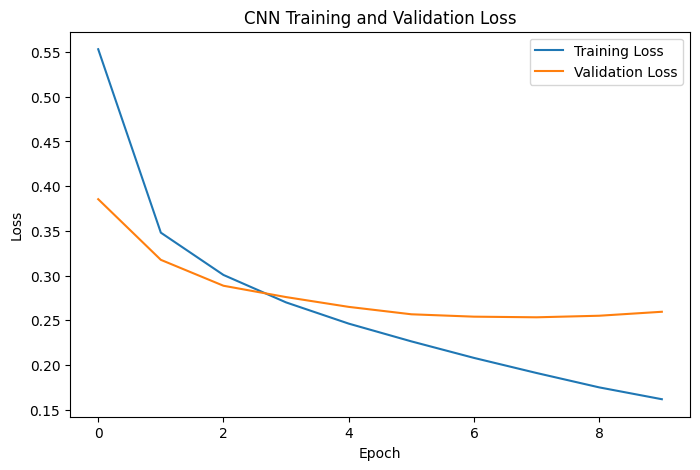

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.savefig(
    "cnn_loss_curve.png",
    bbox_inches="tight"
)

plt.show()

Module 13 — CNN predictions

In [60]:
cnn_model = keras.models.load_model(
    "trained_cnn.keras"
)

print("Trained CNN loaded successfully.")

cnn_train_probabilities = cnn_model.predict(
    X_train_cnn,
    verbose=0
)

cnn_test_probabilities = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_train_predictions = np.argmax(
    cnn_train_probabilities,
    axis=1
)

cnn_test_predictions = np.argmax(
    cnn_test_probabilities,
    axis=1
)

print(
    "CNN training predictions:",
    cnn_train_predictions.shape
)

print(
    "CNN test predictions:",
    cnn_test_predictions.shape
)

Trained CNN loaded successfully.
CNN training predictions: (60000,)
CNN test predictions: (10000,)


Prediction Sanity Check

In [61]:
unique, counts = np.unique(
    cnn_test_predictions,
    return_counts=True
)

prediction_distribution = pd.DataFrame({
    "Class": [
        class_names[i]
        for i in unique
    ],
    "Predictions": counts
})

prediction_distribution

,Class,Predictions
0,T-shirt/top,1051
1,Trouser,978
2,Pullover,992
3,Dress,1018
4,Coat,1109
5,Sandal,1012
6,Shirt,850
7,Sneaker,1063
8,Bag,990
9,Ankle boot,937


Module 14 — CNN metrics

In [62]:
cnn_train_accuracy = accuracy_score(
    y_train,
    cnn_train_predictions
)

cnn_test_accuracy = accuracy_score(
    y_test,
    cnn_test_predictions
)

cnn_train_precision = precision_score(
    y_train,
    cnn_train_predictions,
    average="weighted"
)

cnn_test_precision = precision_score(
    y_test,
    cnn_test_predictions,
    average="weighted"
)

cnn_train_recall = recall_score(
    y_train,
    cnn_train_predictions,
    average="weighted"
)

cnn_test_recall = recall_score(
    y_test,
    cnn_test_predictions,
    average="weighted"
)

cnn_train_f1 = f1_score(
    y_train,
    cnn_train_predictions,
    average="weighted"
)

cnn_test_f1 = f1_score(
    y_test,
    cnn_test_predictions,
    average="weighted"
)

print("CNN Training Accuracy:", cnn_train_accuracy)
print("CNN Test Accuracy:", cnn_test_accuracy)

print("CNN Training Precision:", cnn_train_precision)
print("CNN Test Precision:", cnn_test_precision)

print("CNN Training Recall:", cnn_train_recall)
print("CNN Test Recall:", cnn_test_recall)

print("CNN Training F1:", cnn_train_f1)
print("CNN Test F1:", cnn_test_f1)

print("CNN Training Time:", cnn_training_time)

CNN Training Accuracy: 0.94215
CNN Test Accuracy: 0.9112
CNN Training Precision: 0.9427179753132511
CNN Test Precision: 0.9116210861626598
CNN Training Recall: 0.94215
CNN Test Recall: 0.9112
CNN Training F1: 0.9417288690777552
CNN Test F1: 0.9104154368460738
CNN Training Time: 545.9476542472839


Module 15 — CNN classification report

In [63]:
cnn_report = classification_report(
    y_test,
    cnn_test_predictions,
    target_names=class_names,
    output_dict=True
)

cnn_report_df = pd.DataFrame(cnn_report).transpose()

cnn_report_df

# Save to CSV

cnn_report_df.to_csv(
    "cnn_classification_report.csv"
)

Module 16 — CNN confusion matrices

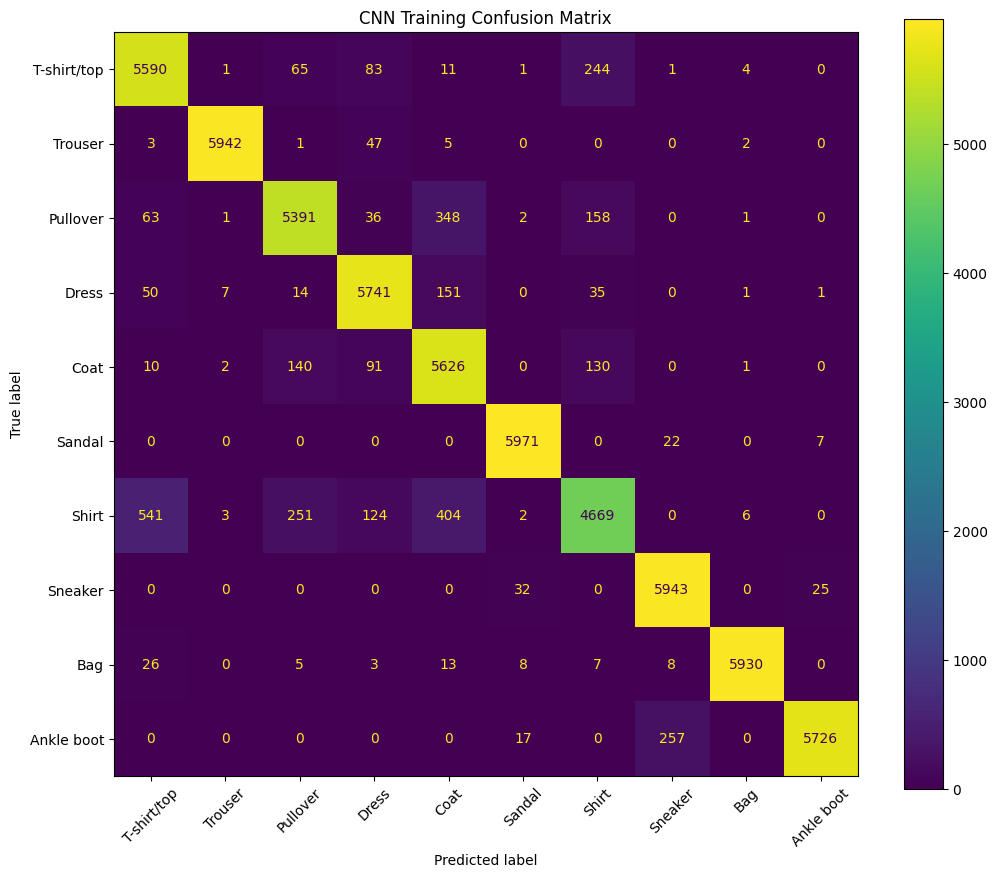

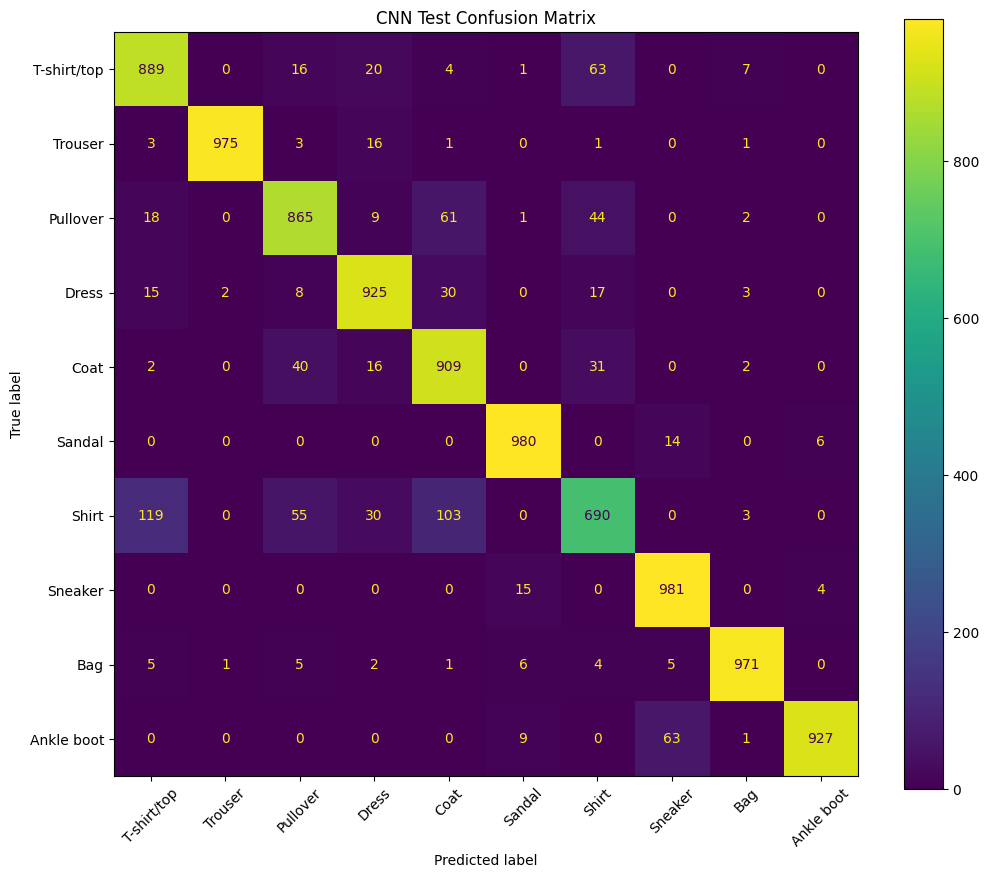

In [64]:
# Train

cnn_train_cm = confusion_matrix(
    y_train,
    cnn_train_predictions
)

disp = ConfusionMatrixDisplay(
    cnn_train_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("CNN Training Confusion Matrix")

plt.savefig(
    "cnn_train_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()


# Test

cnn_test_cm = confusion_matrix(
    y_test,
    cnn_test_predictions
)

disp = ConfusionMatrixDisplay(
    cnn_test_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("CNN Test Confusion Matrix")

plt.savefig(
    "cnn_test_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

Module 17 — Build the Random Forest

In [65]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="entropy",
    max_depth=100,
    random_state=42,
    n_jobs=-1
)

rf_model

RandomForestClassifier(criterion='entropy', max_depth=100, n_jobs=-1,
                       random_state=42)

Module 18 — Train Random Forest

In [66]:
start_time = time.time()

rf_model.fit(
    X_train_rf,
    y_train
)

rf_training_time = time.time() - start_time

print(
    "Random Forest training time:",
    round(rf_training_time, 2),
    "seconds"
)

Random Forest training time: 105.9 seconds


Module 19 — Random Forest predictions

In [67]:
rf_train_predictions = rf_model.predict(
    X_train_rf
)

rf_test_predictions = rf_model.predict(
    X_test_rf
)

Module 20 — Random Forest metrics

In [68]:
rf_train_accuracy = accuracy_score(
    y_train,
    rf_train_predictions
)

rf_test_accuracy = accuracy_score(
    y_test,
    rf_test_predictions
)

rf_train_precision = precision_score(
    y_train,
    rf_train_predictions,
    average="weighted"
)

rf_test_precision = precision_score(
    y_test,
    rf_test_predictions,
    average="weighted"
)

rf_train_recall = recall_score(
    y_train,
    rf_train_predictions,
    average="weighted"
)

rf_test_recall = recall_score(
    y_test,
    rf_test_predictions,
    average="weighted"
)

rf_train_f1 = f1_score(
    y_train,
    rf_train_predictions,
    average="weighted"
)

rf_test_f1 = f1_score(
    y_test,
    rf_test_predictions,
    average="weighted"
)

print("RF Training Accuracy:", rf_train_accuracy)
print("RF Test Accuracy:", rf_test_accuracy)

print("RF Training Precision:", rf_train_precision)
print("RF Test Precision:", rf_test_precision)

print("RF Training Recall:", rf_train_recall)
print("RF Test Recall:", rf_test_recall)

print("RF Training F1:", rf_train_f1)
print("RF Test F1:", rf_test_f1)

print("RF Training Time:", rf_training_time)

RF Training Accuracy: 1.0
RF Test Accuracy: 0.877
RF Training Precision: 1.0
RF Test Precision: 0.8758044183511154
RF Training Recall: 1.0
RF Test Recall: 0.877
RF Training F1: 1.0
RF Test F1: 0.8754554637748304
RF Training Time: 105.89781045913696


Module 21 — Random Forest classification report

In [69]:
rf_report = classification_report(
    y_test,
    rf_test_predictions,
    target_names=class_names,
    output_dict=True
)

rf_report_df = pd.DataFrame(rf_report).transpose()

rf_report_df

# Save

rf_report_df.to_csv(
    "random_forest_classification_report.csv"
)

Module 22 — Random Forest confusion matrices

Train

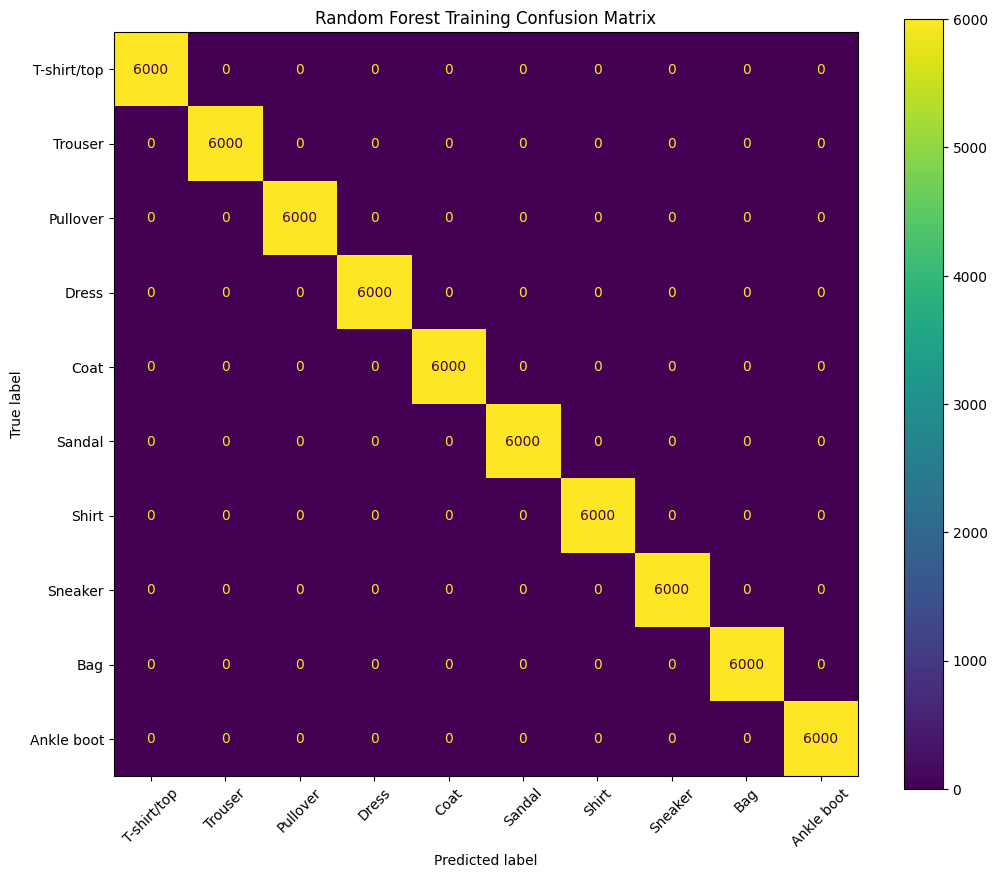

In [70]:
rf_train_cm = confusion_matrix(
    y_train,
    rf_train_predictions
)

disp = ConfusionMatrixDisplay(
    rf_train_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Random Forest Training Confusion Matrix")

plt.savefig(
    "rf_train_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

Test

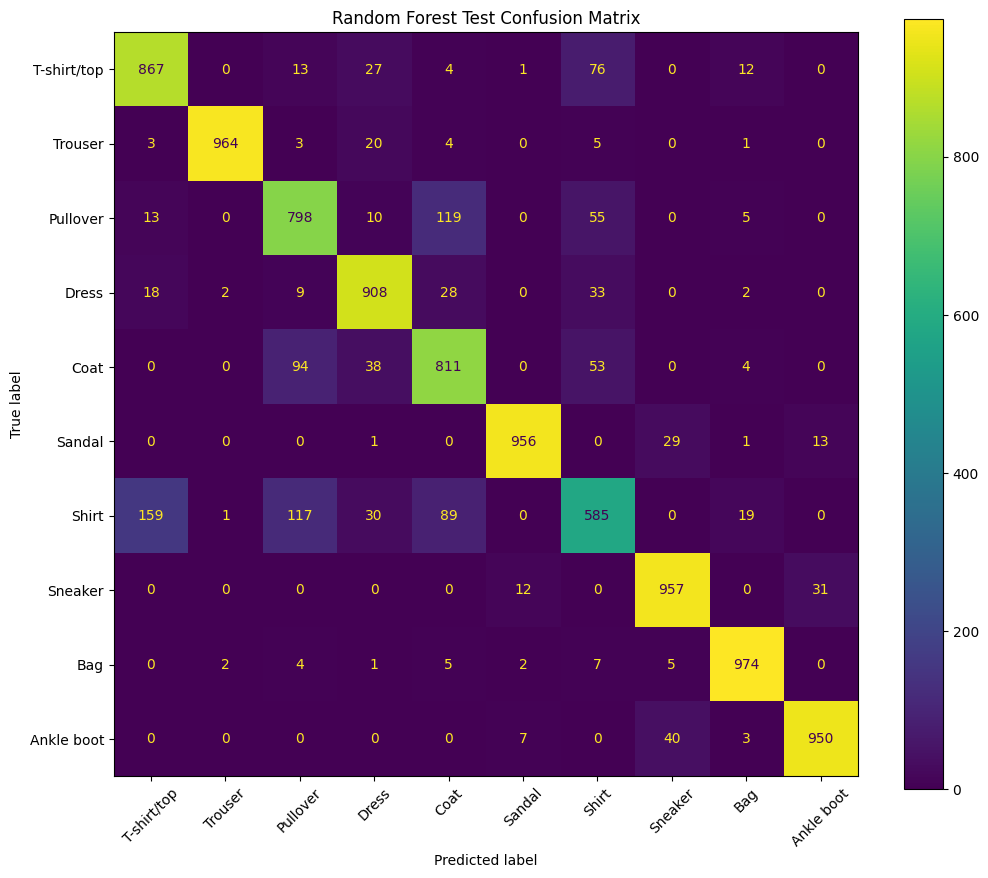

In [71]:
rf_test_cm = confusion_matrix(
    y_test,
    rf_test_predictions
)

disp = ConfusionMatrixDisplay(
    rf_test_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Random Forest Test Confusion Matrix")

plt.savefig(
    "rf_test_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

Module 23 — Final CNN vs Random Forest table

In [72]:
comparison_results = pd.DataFrame({
    "Model": [
        "CNN",
        "Random Forest"
    ],

    "Training Accuracy": [
        cnn_train_accuracy,
        rf_train_accuracy
    ],

    "Test Accuracy": [
        cnn_test_accuracy,
        rf_test_accuracy
    ],

    "Training Precision": [
        cnn_train_precision,
        rf_train_precision
    ],

    "Test Precision": [
        cnn_test_precision,
        rf_test_precision
    ],

    "Training Recall": [
        cnn_train_recall,
        rf_train_recall
    ],

    "Test Recall": [
        cnn_test_recall,
        rf_test_recall
    ],

    "Training F1": [
        cnn_train_f1,
        rf_train_f1
    ],

    "Test F1": [
        cnn_test_f1,
        rf_test_f1
    ],

    "Training Time (seconds)": [
        cnn_training_time,
        rf_training_time
    ]
})

comparison_results

# Save

comparison_results.to_csv(
    "model_comparison.csv",
    index=False
)

Module 24 — Find the worst-performing classes

For The CNN:

In [73]:
cnn_classes = cnn_report_df.loc[class_names]

cnn_classes.sort_values("recall").head()

,precision,recall,f1-score,support
Shirt,0.811765,0.690,0.745946,1000.0
Pullover,0.871976,0.865,0.868474,1000.0
T-shirt/top,0.845861,0.889,0.866894,1000.0
Coat,0.819657,0.909,0.862020,1000.0
Dress,0.908644,0.925,0.916749,1000.0


For Random Forest:

In [74]:
rf_classes = rf_report_df.loc[class_names]

rf_classes.sort_values("recall").head()

,precision,recall,f1-score,support
Shirt,0.718673,0.585,0.644983,1000.0
Pullover,0.768786,0.798,0.783121,1000.0
Coat,0.765094,0.811,0.787379,1000.0
T-shirt/top,0.817925,0.867,0.841748,1000.0
Dress,0.877295,0.908,0.892383,1000.0


Module 25 — Show misclassified CNN images

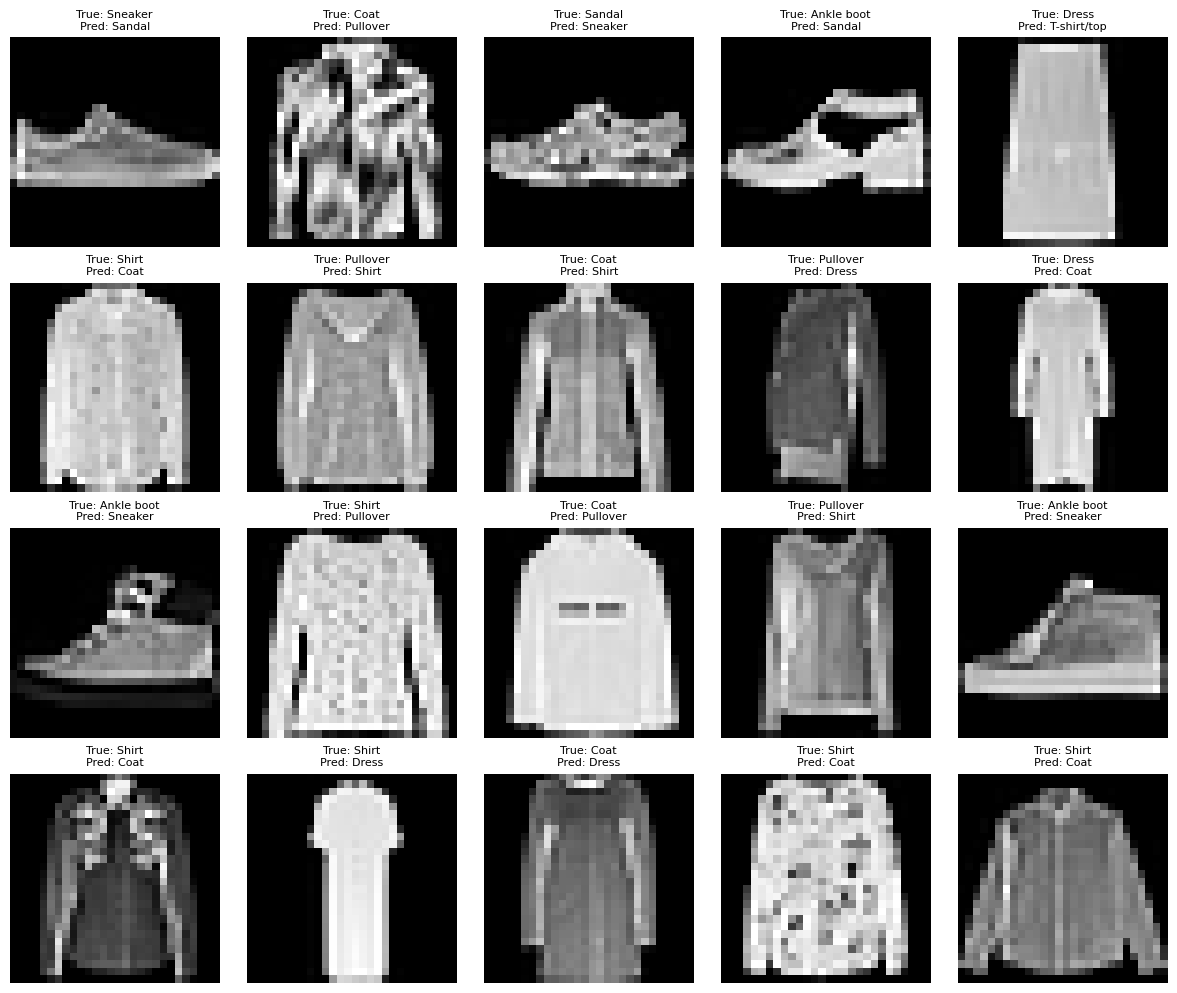

In [75]:
misclassified = np.where(
    cnn_test_predictions != y_test
)[0]

plt.figure(figsize=(12, 10))

for i, index in enumerate(misclassified[:20]):
    plt.subplot(4, 5, i + 1)

    plt.imshow(
        X_test[index],
        cmap="gray"
    )

    actual = class_names[y_test[index]]

    predicted = class_names[
        cnn_test_predictions[index]
    ]

    plt.title(
        f"True: {actual}\nPred: {predicted}",
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "misclassified_examples.png",
    bbox_inches="tight"
)

plt.show()

In [76]:
print("FINAL RESULTS SUMMARY")

print("\nCNN")
print("Test Accuracy:", round(cnn_test_accuracy, 4))
print("Training Time:", round(cnn_training_time, 2), "seconds")

print("\nRandom Forest")
print("Test Accuracy:", round(rf_test_accuracy, 4))
print("Training Time:", round(rf_training_time, 2), "seconds")

print("\nCNN weakest classes:")
print(cnn_classes.sort_values("recall").head(3)[["recall"]])

print("\nRandom Forest weakest classes:")
print(rf_classes.sort_values("recall").head(3)[["recall"]])

FINAL RESULTS SUMMARY

CNN
Test Accuracy: 0.9112
Training Time: 545.95 seconds

Random Forest
Test Accuracy: 0.877
Training Time: 105.9 seconds

CNN weakest classes:
             recall
Shirt         0.690
Pullover      0.865
T-shirt/top   0.889

Random Forest weakest classes:
          recall
Shirt      0.585
Pullover   0.798
Coat       0.811


Module 26 — Final project summary

# Final Summary

The Convolutional Neural Network achieved a test accuracy of **91.12%**, while the Random Forest achieved **87.70%**.

The CNN required approximately **545.95 seconds** to train, compared with **105.90 seconds** for the Random Forest. Although the Random Forest trained considerably faster, the CNN produced the stronger classification performance.

The weakest CNN classes were:

- Shirt — recall: 0.690
- Pullover — recall: 0.865
- T-shirt/top — recall: 0.889

The weakest Random Forest classes were:

- Shirt — recall: 0.585
- Pullover — recall: 0.798
- Coat — recall: 0.811

Both classifiers had greater difficulty distinguishing visually similar upper-body clothing categories. However, the CNN achieved higher overall accuracy and stronger recall on the most difficult categories.

Based on the experimental results, the **CNN is recommended for production** where classification performance is the main priority. The Random Forest remains useful where faster training and lower computational requirements are more important.